# FlowLens: Advanced Process Discovery & Bottlenecks

In this phase, we use **PM4Py** to reconstruct the actual process flow from the event logs. We will generate **Directly Follows Graphs (DFG)** to identify performance bottlenecks and compare the 'Happy Path' against deviant ticket workflows.

In [ ]:
import pandas as pd
import os
os.environ["PATH"] += os.pathsep + r'C:\Program Files\Graphviz\bin'
import pandas as pd
import pm4py
import matplotlib.pyplot as plt

# Load the cleaned event log
df_log = pd.read_csv('../data/processed/Cleaned_EventLog.csv')

# Ensure DateTime format for PM4Py
df_log['Time'] = pd.to_datetime(df_log['Time'])

# Format dataframe for PM4Py
# We map: Case ID -> TicketNum, Activity -> Business_Status, Timestamp -> Time
event_log = pm4py.format_dataframe(df_log, case_id='TicketNum', activity_key='Business_Status', timestamp_key='Time')

print(f"Total Events: {len(event_log)}")
print(f"Total Unique Tickets (Cases): {event_log['TicketNum'].nunique()}")



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing


c:\Users\SHARAN BIRADAR\Desktop\akshara enterprizes\flowlens-process-mining\venv\Lib\site-packages\pm4py\utils.py:254: UserWarning: Some rows of the Pandas data frame have been removed because of empty case IDs, activity labels, or timestamps to ensure the correct functioning of PM4Py's algorithms.
  warnings.warn(


Total Events: 114804
Total Unique Tickets (Cases): 13563


## 1. Process Flow Frequency (Where do tickets go?)
We first generate a frequency-based Directly Follows Graph (DFG) to see the most common paths a ticket takes.

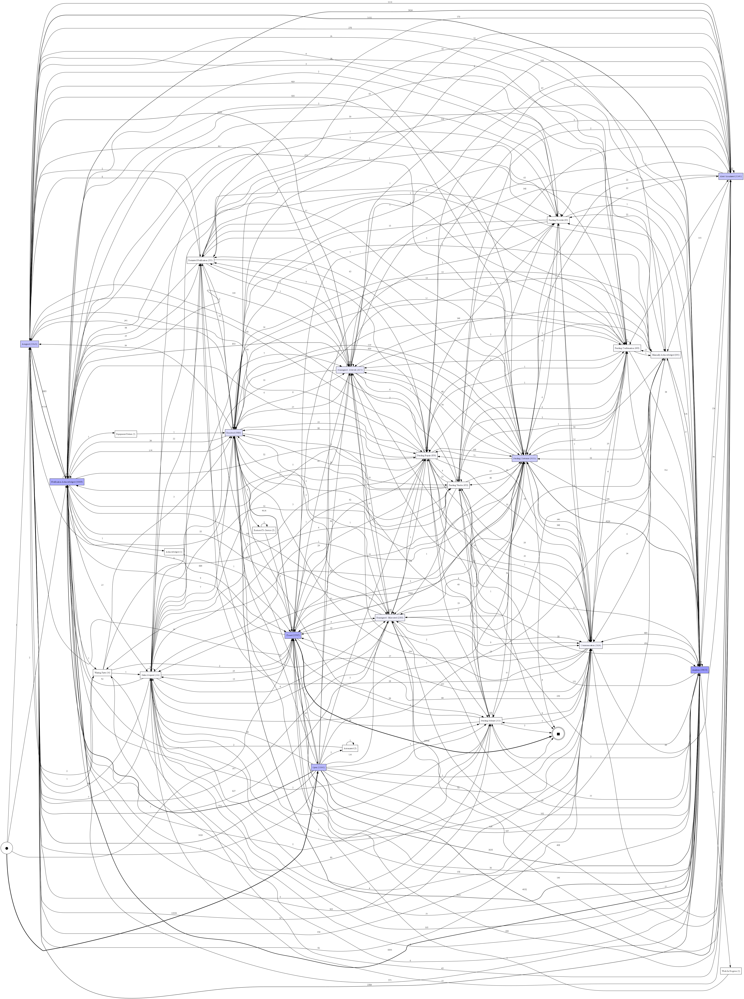

In [2]:
# Discover frequency DFG
dfg, start_activities, end_activities = pm4py.discover_dfg(event_log)

# Visualize frequency DFG
pm4py.view_dfg(dfg, start_activities, end_activities)

## 2. Performance Bottlenecks (Where does time go?)
Next, we generate a performance-based DFG. This shows the average time delay between different statuses. This is crucial for identifying operational bottlenecks (e.g., how long tickets sit in 'Pending Vendor').

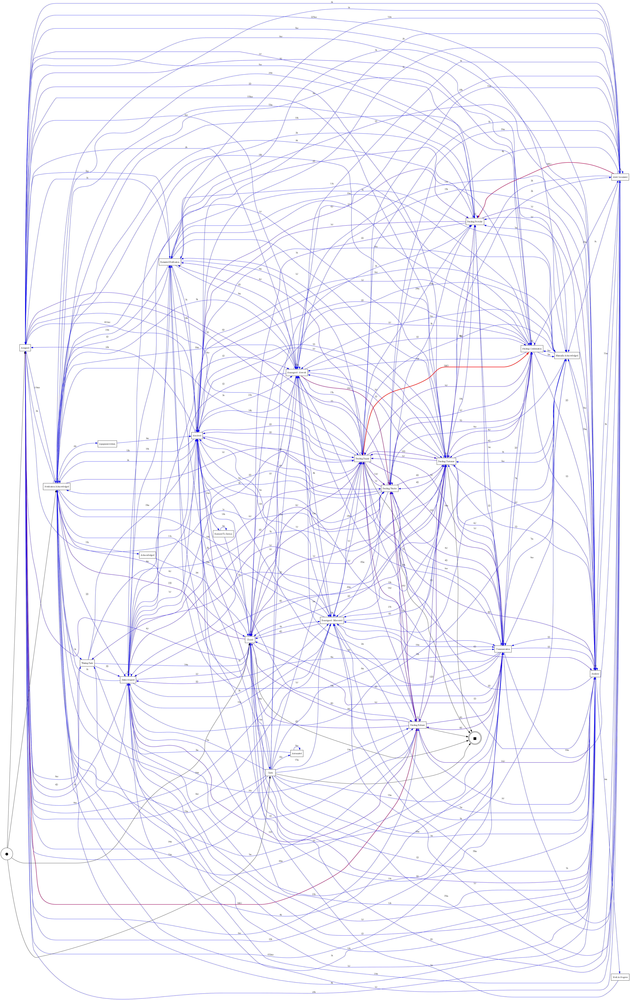

In [3]:
# Discover performance DFG
performance_dfg, start_activities, end_activities = pm4py.discover_performance_dfg(event_log)

# Visualize performance DFG
pm4py.view_performance_dfg(performance_dfg, start_activities, end_activities)

## 3. Process Trees & Model Discovery
Using the Inductive Miner, we can construct a formal Process Tree. This helps us visualize the strict logical flow (AND/XOR/OR gateways) of the IT incident resolution process.

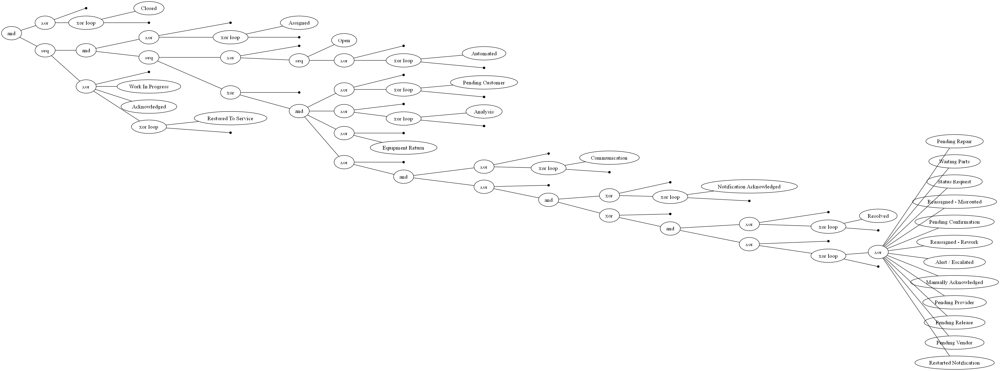

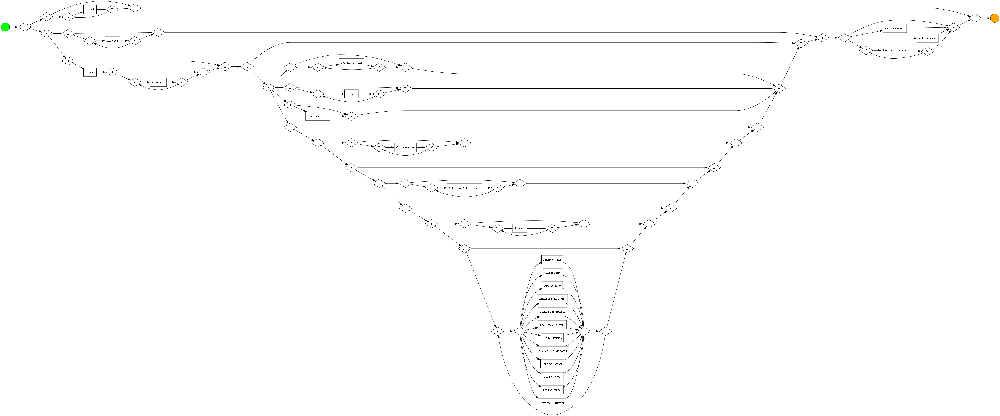

In [4]:
# Discover Process Tree using Inductive Miner
process_tree = pm4py.discover_process_tree_inductive(event_log)

# Visualize Process Tree
pm4py.view_process_tree(process_tree)

# Convert to BPMN and view
bpmn_model = pm4py.convert_to_bpmn(process_tree)
pm4py.view_bpmn(bpmn_model)

## 4. Happy Path vs. Deviant Paths
A major goal of process mining is **Conformance Checking**. Let's extract the most common variants (the "Happy Path") and see what percentage of tickets follow the ideal workflow.

In [5]:
# Extract process variants
variants = pm4py.get_variants(event_log)
print(f"Total Unique Process Variants: {len(variants)}")

# Get the top 5 most common variants
from pm4py.statistics.traces.generic.log import case_statistics
variants_count = case_statistics.get_variant_statistics(event_log)
variants_count = sorted(variants_count, key=lambda x: x['count'], reverse=True)

print("\nTop 5 Most Common 'Happy Paths':")
for var in variants_count[:5]:
    print(f"{var['count']} tickets: {var['variant']}")

Total Unique Process Variants: 4781

Top 5 Most Common 'Happy Paths':
973 tickets: ('Open', 'Notification Acknowledged', 'Analysis', 'Closed')
719 tickets: ('Open', 'Notification Acknowledged', 'Analysis', 'Resolved', 'Closed')
419 tickets: ('Open', 'Notification Acknowledged', 'Closed')
343 tickets: ('Open', 'Notification Acknowledged', 'Analysis', 'Analysis', 'Closed')
234 tickets: ('Open', 'Notification Acknowledged', 'Assigned', 'Analysis', 'Resolved', 'Closed')
